## 1. Contexte et objectif

Ce notebook s'appuie sur le dataset [Electrical Fault Detection and Classification](https://www.kaggle.com/datasets/esathyaprakash/electrical-fault-detection-and-classification) : une ligne de transport simulée sous MATLAB/Simulink, alimentée par quatre générateurs de 11 kV, avec des défauts provoqués au milieu de la ligne. Les données contiennent les courants des trois phases et les tensions entre phases dans six situations : fonctionnement normal et cinq types de défaut (phase-terre, biphasé, biphasé-terre, triphasé et triphasé-terre).

L'objectif est de reconnaître le type de défaut à partir de ces six mesures, comme doit le faire une protection de ligne, vite et sans se tromper. Mais surtout, je veux vérifier si le score obtenu est fiable : on verra qu'une précision de 99,7 % peut cacher une fuite de données, et que la physique du réseau aide à comprendre les erreurs du modèle.

## 2. Chargement et qualité des données

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [2]:
# Chemin du dossier des données, à partir du dossier du notebook
path = "data/"
df = pd.read_csv(path+"classData.csv")
print(df.shape)

(7861, 10)


In [3]:
df.head()

,G,C,B,A,Ia,Ib,Ic,Va,Vb,Vc
0,1,0,0,1,-151.291812,-9.677452,85.800162,0.400750,-0.132935,-0.267815
1,1,0,0,1,-336.186183,-76.283262,18.328897,0.312732,-0.123633,-0.189099
2,1,0,0,1,-502.891583,-174.648023,-80.924663,0.265728,-0.114301,-0.151428
3,1,0,0,1,-593.941905,-217.703359,-124.891924,0.235511,-0.104940,-0.130570
4,1,0,0,1,-643.663617,-224.159427,-132.282815,0.209537,-0.095554,-0.113983


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7861 entries, 0 to 7860
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   G       7861 non-null   int64  
 1   C       7861 non-null   int64  
 2   B       7861 non-null   int64  
 3   A       7861 non-null   int64  
 4   Ia      7861 non-null   float64
 5   Ib      7861 non-null   float64
 6   Ic      7861 non-null   float64
 7   Va      7861 non-null   float64
 8   Vb      7861 non-null   float64
 9   Vc      7861 non-null   float64
dtypes: float64(6), int64(4)
memory usage: 614.3 KB


In [5]:
df.isnull().sum()

G     0
C     0
B     0
A     0
Ia    0
Ib    0
Ic    0
Va    0
Vb    0
Vc    0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

Le fichier contient 7 861 lignes et 10 colonnes :
- **G, C, B, A** : les étiquettes du défaut. Chaque colonne vaut 1 si la terre (G) ou la phase correspondante (A, B ou C) est impliquée dans le défaut, et 0 sinon.
- **Ia, Ib, Ic** : les courants des trois phases.
- **Va, Vb, Vc** : les tensions entre phases (tensions composées), comme le montre la partie 3.
Il n'y a ni valeur manquante ni doublon, et chaque colonne a le bon type : le dataset ne demande aucun nettoyage.

## 3. Exploration des types de défaut

In [7]:
df["type_defaut"]=df["G"].astype(str) + df["C"].astype(str) + df["B"].astype(str) + df["A"].astype(str)
comptage = df["type_defaut"].value_counts()

In [8]:
print(comptage)

type_defaut
0000    2365
1011    1134
1111    1133
1001    1129
0111    1096
0110    1004
Name: count, dtype: int64


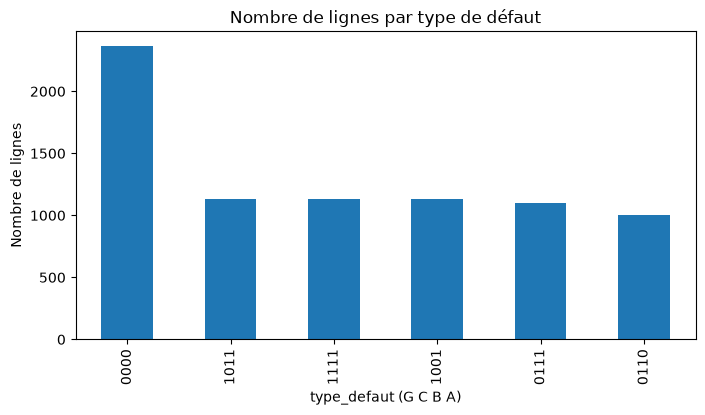

In [9]:
plt.figure(figsize=(8, 4))
comptage.plot(kind="bar")
plt.title("Nombre de lignes par type de défaut")
plt.xlabel("type_defaut (G C B A)")
plt.ylabel("Nombre de lignes")
plt.show()

Les quatre étiquettes sont regroupées dans une seule colonne `type_defaut` (dans l'ordre G, C, B, A) :

| Code | Type de défaut |
|---|---|
| `0000` | Pas de défaut |
| `1001` | Phase A - terre |
| `0110` | Phases B - C |
| `1011` | Phases A - B - terre |
| `0111` | Phases A - B - C (triphasé) |
| `1111` | Phases A - B - C - terre (triphasé-terre) |

Chaque type de défaut compte entre 1 004 et 1 134 lignes, et la classe « pas de défaut » en compte 2 365, soit environ deux fois plus. Les classes sont assez équilibrées : pas besoin de les rééquilibrer.

In [10]:

mesures = ["Ia", "Ib", "Ic", "Va", "Vb", "Vc"]
resume = df[mesures].abs().groupby(df["type_defaut"]).mean()
resume = resume.round(2)
print(resume)

                 Ia      Ib      Ic    Va    Vb    Vc
type_defaut                                          
0000          41.07   46.61   44.75  0.39  0.38  0.39
0110          39.99  502.02  483.70  0.32  0.03  0.35
0111         547.31  547.30  523.20  0.03  0.06  0.06
1001         558.75   44.66   31.76  0.24  0.38  0.22
1011         552.97  517.24   35.69  0.04  0.26  0.22
1111         560.43  514.68  505.69  0.04  0.07  0.05


In [11]:
somme_tensions = df["Va"] + df["Vb"] + df["Vc"]

print("Amplitude max des tensions :", df[["Va", "Vb", "Vc"]].abs().max().max())

print(somme_tensions.abs().groupby(df["type_defaut"]).max())

Amplitude max des tensions : 0.627874757
type_defaut
0000    1.900000e-08
0110    1.000000e-09
0111    3.300000e-08
1001    1.000000e-09
1011    4.600000e-08
1111    4.000000e-08
dtype: float64


Le tableau donne la moyenne de la valeur absolue de chaque mesure par type de défaut. Les signaux sont alternatifs, donc leur moyenne simple serait proche de 0.

**Courants :** sans défaut, ils restent faibles (40 à 47). Dès qu'une phase est touchée, son courant monte à environ 480 à 560. Le nombre de courants élevés indique donc le nombre de phases en défaut.

**Tensions :** la somme Va + Vb + Vc reste inférieure à 5 × 10⁻⁸, même pendant les défauts à la terre. Ce ne sont donc pas des tensions phase-terre. Le tableau montre que ce sont des tensions composées : Va, Vb et Vc correspondent à Uab, Ubc et Uca.
- `1001` (A - terre) : Uab et Uca, qui font intervenir la phase A, passent de 0,39 à environ 0,23 (soit 0,39 / √3), alors qu'Ubc ne bouge pas.
- `0110` (B - C) : Ubc s'annule (0,03), alors qu'Uab et Uca baissent à peine.
- `0111` et `1111` : les trois tensions s'effondrent, et les moyennes des deux classes sont presque identiques. Seule la présence de la terre les distingue.

Les mesures respectent la physique, et chaque type de défaut a une signature différente : la classification est faisable.

## 4. Premier modèle

In [12]:
X = df[mesures]
y = df["type_defaut"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Entraînement :", X_train.shape)
print("Test :", X_test.shape)

Entraînement : (6288, 6)
Test : (1573, 6)


In [13]:

modele = RandomForestClassifier(random_state=42)

modele.fit(X_train, y_train)

y_pred = modele.predict(X_test)

precision = accuracy_score(y_test, y_pred)

print("Précision :", precision)

Précision : 0.8728544183089637


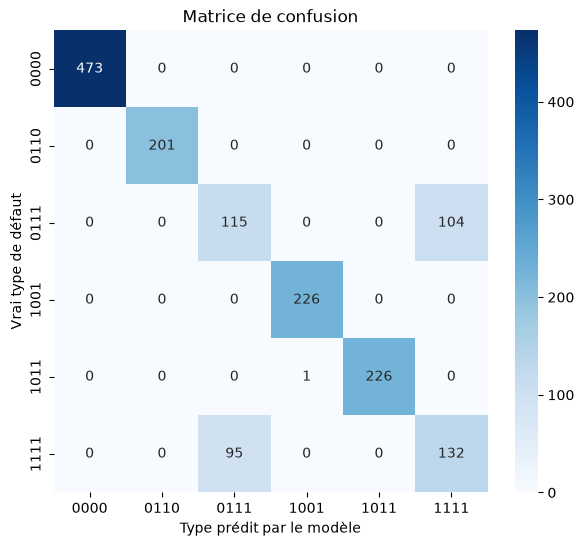

In [14]:
classes = sorted(y.unique())

matrice = confusion_matrix(y_test, y_pred, labels=classes)

plt.figure(figsize=(7, 6))

sns.heatmap(matrice, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)

plt.xlabel("Type prédit par le modèle")

plt.ylabel("Vrai type de défaut")

plt.title("Matrice de confusion")

plt.show()

**Méthode :** les 6 mesures servent d'entrées (X) et le type de défaut de cible (y). Les lignes sont réparties au hasard : 80 % pour l'entraînement et 20 % pour le test, avec les mêmes proportions de classes dans les deux jeux. Le modèle est une forêt aléatoire, c'est-à-dire un ensemble d'arbres de décision qui votent pour le type de défaut.

**Résultat :** 87,4 % de bonnes prédictions. Quatre classes sur six sont reconnues presque parfaitement, et 197 des 198 erreurs viennent de la confusion entre `0111` et `1111`. C'était prévisible : dans la partie 3, ces deux classes avaient des moyennes presque identiques. Le modèle ne sait pas dire si un défaut triphasé touche aussi la terre.

## 5. Une variable tirée de la physique : le courant résiduel

In [15]:
df["Isomme"] = df["Ia"] + df["Ib"] + df["Ic"]

resume_terre = df.groupby("type_defaut")["Isomme"].agg(["mean", "std"])

resume_terre = resume_terre.round(2)

print(resume_terre)

              mean     std
type_defaut               
0000         -3.08    4.20
0110          2.52    0.14
0111          2.09    0.06
1001         35.45  656.99
1011        -60.27  642.22
1111         49.85  162.48


Le courant résiduel est la somme des trois courants :

$$I_{somme} = I_a + I_b + I_c$$

D'après la loi des nœuds, il est nul quand aucun courant ne part à la terre. C'est la grandeur que surveillent les protections de terre.

Le tableau le confirme : son écart-type reste faible pour les défauts sans terre (4,2 au maximum) et devient grand pour les défauts à la terre (160 à 660). Or une forêt aléatoire pose ses questions sur une seule variable à la fois : elle voit Ia, Ib et Ic séparément, mais elle a du mal à calculer leur somme. On lui donne donc directement `Isomme`.

In [16]:
mesures2 = ["Ia", "Ib", "Ic", "Va", "Vb", "Vc", "Isomme"]

Précision sans Isomme : 0.8728544183089637
Précision avec Isomme : 0.9974570883661793


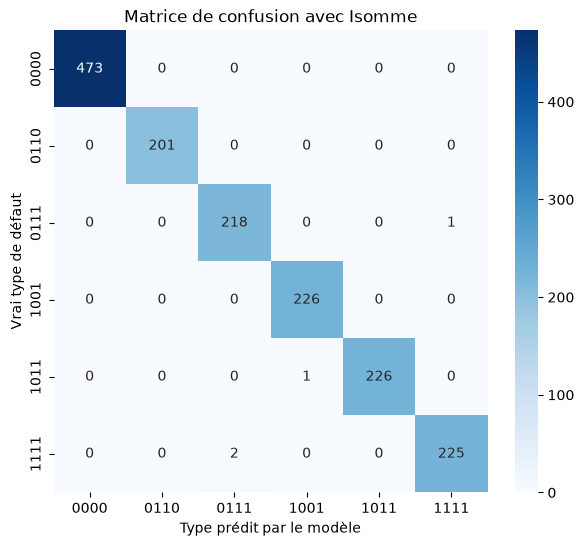

In [17]:
X2 = df[mesures2]
X2_train, X2_test, y_train, y_test = train_test_split(X2, y, test_size=0.2, stratify=y, random_state=42)

modele2 = RandomForestClassifier(random_state=42)

modele2.fit(X2_train, y_train)

y_pred2 = modele2.predict(X2_test)

precision2 = accuracy_score(y_test, y_pred2)

print("Précision sans Isomme :", precision)
print("Précision avec Isomme :", precision2)

matrice2 = confusion_matrix(y_test, y_pred2, labels=classes)

plt.figure(figsize=(7, 6))

sns.heatmap(matrice2, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)

plt.xlabel("Type prédit par le modèle")

plt.ylabel("Vrai type de défaut")

plt.title("Matrice de confusion avec Isomme")

plt.show()

**Résultat :** avec `Isomme` en plus des 6 mesures, la précision passe de 87,4 % à 99,7 %. Avec le même découpage des données, la confusion entre `0111` et `1111` tombe de 197 erreurs à 3.

Ce score paraît excellent, mais deux questions restent ouvertes. Le découpage au hasard est-il adapté à ces données ? C'est l'objet de la partie 6. Et `Isomme` sépare-t-il vraiment ces deux classes pour une raison physique ? Réponse dans les parties 7 et 8.

## 6. Une évaluation plus honnête : le découpage temporel

type_defaut
1001    300
Name: count, dtype: int64


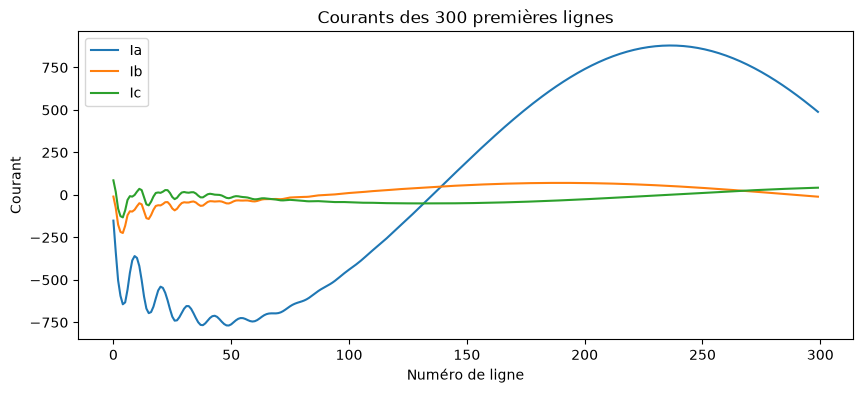

In [18]:
print(df["type_defaut"].iloc[:300].value_counts())

extrait = df[["Ia", "Ib", "Ic"]].iloc[:300]

plt.figure(figsize=(10, 4))

plt.plot(extrait.index, extrait["Ia"], label="Ia")

plt.plot(extrait.index, extrait["Ib"], label="Ib")

plt.plot(extrait.index, extrait["Ic"], label="Ic")

plt.xlabel("Numéro de ligne")

plt.ylabel("Courant")

plt.title("Courants des 300 premières lignes")

plt.legend()

plt.show()

In [19]:
precedent = df["type_defaut"].shift()

debut_bloc = df["type_defaut"] != precedent

print("Nombre de blocs :", debut_bloc.sum())

print(df.loc[debut_bloc, "type_defaut"])

Nombre de blocs : 6
0       1001
1129    1011
2263    0110
3267    0111
4363    1111
5496    0000
Name: type_defaut, dtype: str


**Les lignes sont des instants successifs.** Sur le graphique, le courant Ia d'un défaut phase A - terre suit une sinusoïde après un court régime transitoire, et une période dure environ 400 lignes. Avec le pas de simulation indiqué sur le schéma Simulink du dataset (5 × 10⁻⁵ s), on retrouve exactement la fréquence du réseau :

$$400 \times 5 \cdot 10^{-5}\ \text{s} = 20\ \text{ms} \quad \Rightarrow \quad f = 50\ \text{Hz}$$

**Chaque type de défaut forme un seul bloc.** Le fichier contient 6 blocs, un par type. Chaque type correspond donc à un seul enregistrement très court : 1 000 à 1 130 lignes, soit 50 à 57 ms, à peine 3 périodes (environ 6 pour la classe « pas de défaut »).

**Conséquence :** deux lignes voisines sont presque identiques. Avec un découpage au hasard, chaque ligne de test a ses voisines immédiates dans l'entraînement, et le score devient trop optimiste.

Entraînement : (6292, 7) | Test : (1569, 7)
Précision, découpage au hasard : 0.9974570883661793
Précision, découpage temporel : 0.8247291268323773


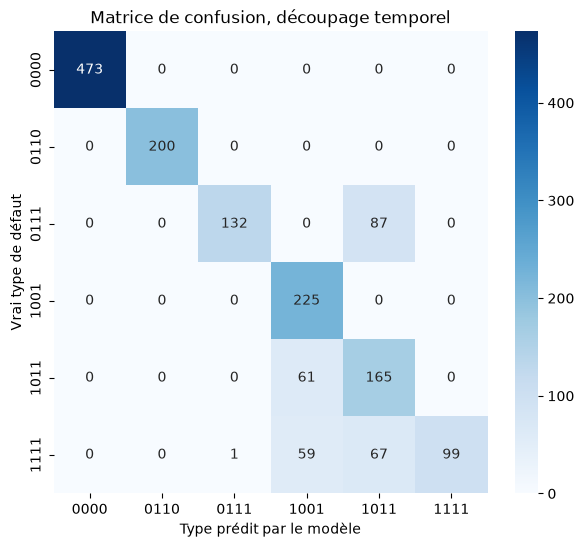

In [20]:
position = df.groupby("type_defaut").cumcount()

taille = df.groupby("type_defaut")["type_defaut"].transform("size")

test_temporel = position >= 0.8 * taille

X_train_t = X2[~test_temporel]

y_train_t = y[~test_temporel]

X_test_t = X2[test_temporel]

y_test_t = y[test_temporel]

print("Entraînement :", X_train_t.shape, "| Test :", X_test_t.shape)

modele_t = RandomForestClassifier(random_state=42)

modele_t.fit(X_train_t, y_train_t)

y_pred_t = modele_t.predict(X_test_t)

precision_t = accuracy_score(y_test_t, y_pred_t)

print("Précision, découpage au hasard :", precision2)

print("Précision, découpage temporel :", precision_t)

matrice_t = confusion_matrix(y_test_t, y_pred_t, labels=classes)

plt.figure(figsize=(7, 6))

sns.heatmap(matrice_t, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)

plt.xlabel("Type prédit par le modèle")

plt.ylabel("Vrai type de défaut")

plt.title("Matrice de confusion, découpage temporel")

plt.show()

**Méthode :** dans chaque bloc, les 80 % premières lignes servent à l'entraînement et les 20 % dernières au test. Le modèle est ainsi évalué sur la fin de chaque enregistrement, qu'il n'a jamais vue.

**Résultat :** la précision tombe de 99,7 % à 82,5 %. Le 99,7 % était donc trop optimiste : avec le découpage au hasard, le modèle reconnaissait surtout des instants voisins de ceux qu'il avait appris. C'est une fuite de données (data leakage) classique sur les séries temporelles.

`0000`, `0110` et `1001` restent parfaitement reconnus. Les erreurs se concentrent sur `0111` (souvent pris pour `1011`), `1011` (pris pour `1001`) et surtout `1111`, reconnu moins d'une fois sur deux. La partie 7 explique pourquoi.

## 7. Analyse des erreurs : l'élimination du défaut

Frontière entraînement/test : 5270


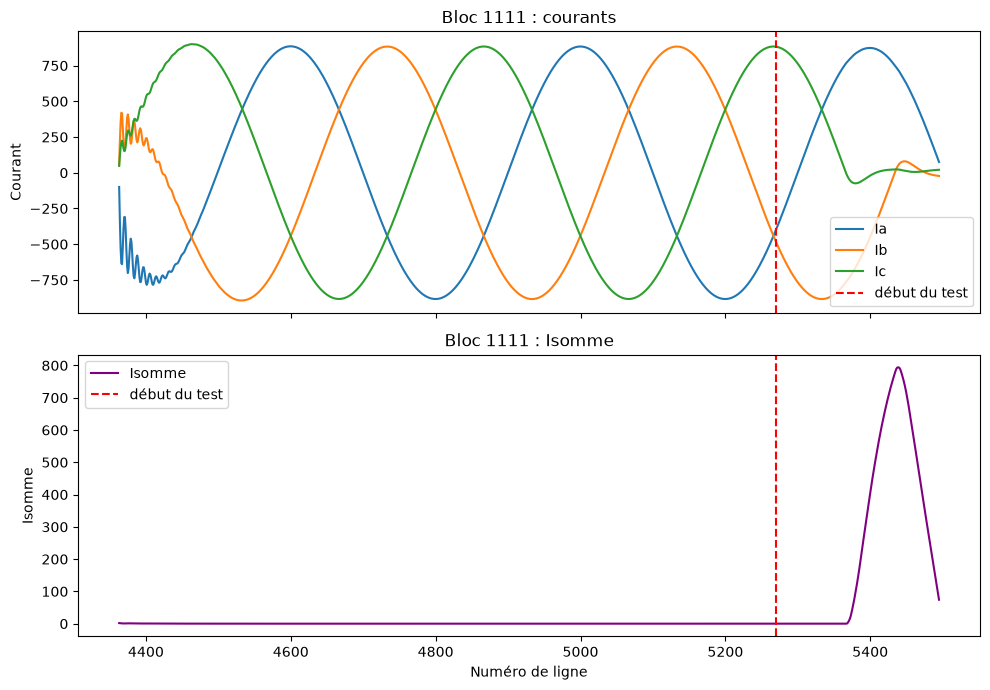

In [21]:
bloc = df[df["type_defaut"] == "1111"]
frontiere = df[test_temporel & (df["type_defaut"] == "1111")].index[0]
print("Frontière entraînement/test :", frontiere)
fig, (haut, bas) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
haut.plot(bloc.index, bloc["Ia"], label="Ia")
haut.plot(bloc.index, bloc["Ib"], label="Ib")
haut.plot(bloc.index, bloc["Ic"], label="Ic")
haut.axvline(frontiere, color="red", linestyle="--", label="début du test")
haut.set_title("Bloc 1111 : courants")
haut.set_ylabel("Courant")
haut.legend()
bas.plot(bloc.index, bloc["Isomme"], color="purple", label="Isomme")
bas.axvline(frontiere, color="red", linestyle="--", label="début du test")
bas.set_title("Bloc 1111 : Isomme")
bas.set_xlabel("Numéro de ligne")
bas.set_ylabel("Isomme")
bas.legend()
plt.tight_layout()
plt.show()


L'enregistrement `1111` se découpe en trois moments :
1. **Début :** le régime transitoire à l'apparition du défaut.
2. **Milieu :** un défaut triphasé symétrique, avec `Isomme` ≈ 0.
3. **Fin (à partir de la ligne 5 375 environ, entièrement dans le test) :** Ic puis Ib s'annulent l'un après l'autre, alors que le courant Ia continue. C'est la signature de l'élimination du défaut, phase par phase, au passage par zéro de chaque courant.

Pendant cette élimination, le défaut n'est plus triphasé. Une fois la phase C coupée, il reste un défaut A - B - terre, qui ressemble à `1011`. Une fois la phase B coupée aussi, il ne reste qu'un défaut A - terre, qui ressemble à `1001`. C'est exactement ce que prédit le modèle : 67 fois `1011` et 59 fois `1001`.

Ces « erreurs » décrivent donc l'état physique réel à ces instants. Le problème vient de l'étiquette, qui décrit le scénario entier et non chaque instant. Les erreurs sur `0111` et `1011` ont probablement la même cause. Avec le découpage au hasard, ces instants se trouvaient aussi dans l'entraînement, et le modèle les avait appris par cœur.

On remarque aussi que le courant de terre du `1111` n'apparaît qu'à l'élimination du défaut : pendant le défaut établi, `Isomme` reste quasi nul, comme le prévoit la théorie.

In [22]:
milieu = (position >= 100) & (position < 900)
triphase = df["type_defaut"].isin(["0111", "1111"])
regime_etabli = df[milieu & triphase]
print(regime_etabli.groupby("type_defaut")["Isomme"].describe())

             count      mean       std       min       25%       50%  \
type_defaut                                                            
0111         800.0  2.089006  0.046389  2.009830  2.048783  2.088492   
1111         800.0  0.004750  0.019816 -0.002264 -0.002264 -0.002248   

                  75%       max  
type_defaut                      
0111         2.128970  2.170233  
1111        -0.000851  0.121809  


Pendant le défaut établi (lignes 100 à 900 de chaque enregistrement), les plages de `Isomme` ne se chevauchent pas : de 2,01 à 2,17 pour `0111`, et de -0,002 à 0,12 pour `1111`. Le modèle sépare donc ces deux classes grâce à un décalage constant d'environ 2 sur `0111`. Rapporté à l'amplitude des courants de défaut (environ 880), cela donne :

$$\frac{2}{880} \approx 0{,}2\,\%$$

Physiquement, ces deux défauts sont symétriques et ne font pas circuler de courant de terre en régime établi. Ce décalage est donc un artefact de la simulation, et non une signature physique. Un vrai capteur de courant a une erreur de l'ordre de 0,5 à 1 %, plus grande que cet écart. La partie 8 vérifie ce que devient le modèle avec du bruit de mesure.

## 8. Robustesse au bruit et modèle final

Précision, découpage temporel, sans bruit : 0.8247291268323773
Précision, découpage temporel, avec 1 % de bruit : 0.7380497131931166


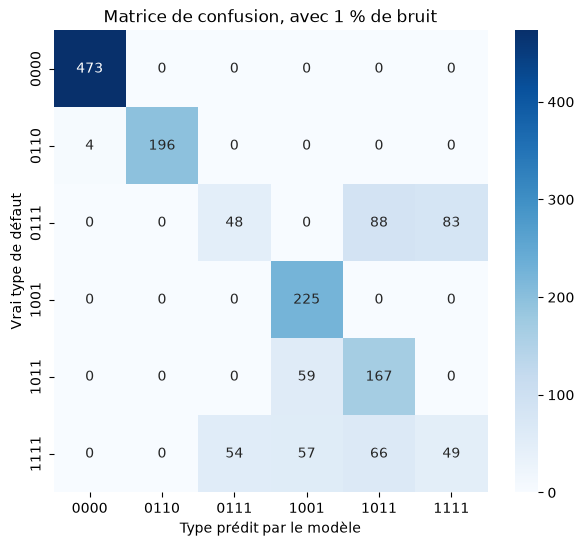

In [23]:
rng = np.random.default_rng(42)

df_bruit = df.copy()

for col in ["Ia", "Ib", "Ic", "Va", "Vb", "Vc"]:
    amplitude = df[col].abs().max()
    df_bruit[col] = df[col] + rng.normal(0, 0.01 * amplitude, len(df))

df_bruit["Isomme"] = df_bruit["Ia"] + df_bruit["Ib"] + df_bruit["Ic"]

X_bruit = df_bruit[mesures2]

X_train_b = X_bruit[~test_temporel]

X_test_b = X_bruit[test_temporel]

modele_b = RandomForestClassifier(random_state=42)

modele_b.fit(X_train_b, y_train_t)

y_pred_b = modele_b.predict(X_test_b)

precision_b = accuracy_score(y_test_t, y_pred_b)

print("Précision, découpage temporel, sans bruit :", precision_t)
print("Précision, découpage temporel, avec 1 % de bruit :", precision_b)

matrice_b = confusion_matrix(y_test_t, y_pred_b, labels=classes)
plt.figure(figsize=(7, 6))
sns.heatmap(matrice_b, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Type prédit par le modèle")
plt.ylabel("Vrai type de défaut")
plt.title("Matrice de confusion, avec 1 % de bruit")

plt.show()

**Méthode :** on ajoute à chacune des 6 mesures un bruit gaussien dont l'écart-type vaut 1 % de son amplitude maximale, un ordre de grandeur réaliste pour un capteur. `Isomme` est recalculé à partir des courants bruités, comme le ferait un vrai relais. Le découpage temporel reste le même.

**Résultat :** la précision passe de 82,5 % à 73,8 %, et la confusion entre `0111` et `1111` revient : 137 erreurs entre ces deux classes, contre 1 sans bruit. Le bruit a noyé le décalage d'environ 2, et pendant le défaut établi, le modèle choisit presque au hasard entre les deux. Les erreurs dues à l'élimination du défaut, elles, n'ont presque pas changé.

Avec ces mesures, `0111` et `1111` ne peuvent donc pas être distingués physiquement en régime établi.

Précision, 6 classes, avec bruit : 0.7380497131931166
Précision, 5 classes, avec bruit : 0.8272785213511791


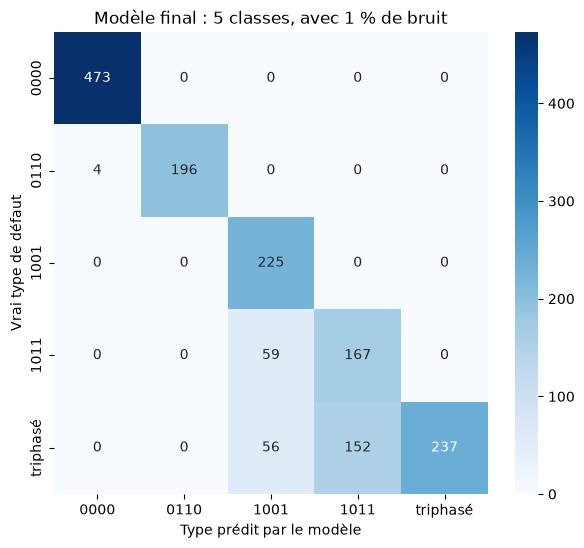

In [24]:
y_fusion = y.replace({"0111": "triphasé", "1111": "triphasé"})

y_train_f = y_fusion[~test_temporel]
y_test_f = y_fusion[test_temporel]

modele_f = RandomForestClassifier(random_state=42)
modele_f.fit(X_train_b, y_train_f)
y_pred_f = modele_f.predict(X_test_b)

precision_f = accuracy_score(y_test_f, y_pred_f)
print("Précision, 6 classes, avec bruit :", precision_b)
print("Précision, 5 classes, avec bruit :", precision_f)

classes_f = sorted(y_fusion.unique())
matrice_f = confusion_matrix(y_test_f, y_pred_f, labels=classes_f)

plt.figure(figsize=(7, 6))
sns.heatmap(matrice_f, annot=True, fmt="d", cmap="Blues", xticklabels=classes_f, yticklabels=classes_f)
plt.xlabel("Type prédit par le modèle")
plt.ylabel("Vrai type de défaut")
plt.title("Modèle final : 5 classes, avec 1 % de bruit")

plt.show()

**Fusion de `0111` et `1111` :** la physique ne permet pas de distinguer ces deux classes, et une protection les traite de la même façon, en déclenchant les trois phases. On les regroupe donc dans une seule classe « triphasé ».

**Résultat :** 82,7 % de bonnes prédictions sur 5 classes, avec bruit et découpage temporel. `0000`, `0110` et `1001` sont reconnus presque parfaitement (4 erreurs sur `0110`). Toutes les autres erreurs vont dans le même sens, vers un défaut qui touche moins de phases (triphasé → `1011` → `1001`). C'est la signature de l'élimination du défaut phase par phase, vue dans la partie 7.

## 9. Conclusion et limites

| Étape | Précision |
|---|---|
| Premier modèle, découpage au hasard | 87,4 % |
| + courant résiduel `Isomme`, découpage au hasard | 99,7 % |
| Découpage temporel | 82,5 % |
| Découpage temporel + 1 % de bruit | 73,8 % |
| **Modèle final : 5 classes, bruit, découpage temporel** | **82,7 %** |

**Ce que montre ce projet :**
- Sur des séries temporelles, un découpage au hasard gonfle le score : le modèle reconnaît des instants voisins de ceux qu'il a appris. Le 99,7 % tombe à 82,5 % dès qu'on teste sur une partie de l'enregistrement jamais vue.
- La physique du réseau sert à chaque étape : pour créer une variable (le courant résiduel), pour vérifier la nature des mesures (des tensions composées) et pour expliquer les erreurs (l'élimination du défaut phase par phase).
- Un bon score ne garantit pas une bonne raison : la séparation de `0111` et `1111` reposait sur un décalage de 0,2 % dû à la simulation, qui disparaît avec un bruit de mesure réaliste.

**Limites :**
- Un seul enregistrement court par type de défaut (environ 3 périodes) : une seule résistance de défaut, un seul instant d'apparition et un seul emplacement. Le modèle n'est pas testé dans d'autres conditions.
- Les étiquettes décrivent le scénario entier et non l'état réel à chaque instant : la phase d'élimination garde l'étiquette du défaut initial.
- Les unités ne sont pas documentées dans le dataset.

**Pistes :** simuler de nombreux défauts dans des conditions variées et tester sur des enregistrements entiers jamais vus, étiqueter chaque instant selon l'état réel, et calculer des grandeurs sur une période complète (valeurs efficaces, composantes symétriques), plus proches de ce qu'utilise une vraie protection.